In [ ]:
#import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,LabelEncoder
from sklearn.impute import SimpleImputer

In [ ]:
#load the dataset
titanic_df=pd.read_csv('/content/titanic_data.csv')
print('Dataset loaded successfully')

Dataset loaded successfully


In [ ]:
titanic_df.shape

(891, 12)

In [ ]:
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
titanic_df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
#Duplicate rows
print(titanic_df.duplicated().sum())

0


In [ ]:
#Fill missing values
titanic_df.Age.fillna(titanic_df.Age.mean(),inplace=True)
titanic_df.Embarked.fillna(titanic_df.Embarked.mode()[0],inplace=True)

/tmp/ipykernel_582/32674806.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_df.Age.fillna(titanic_df.Age.mean(),inplace=True)
/tmp/ipykernel_582/32674806.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', t

In [ ]:
#drop cabin and check null values
titanic_df.drop('Cabin',axis=1,inplace=True)

In [ ]:
titanic_df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
#create labelEncoder
le=LabelEncoder()
#Apply labelEncoding to column Sex
titanic_df['Sex']=le.fit_transform(titanic_df['Sex'])
print(titanic_df['Sex'].head())

0    1
1    0
2    0
3    0
4    1
Name: Sex, dtype: int64


In [ ]:
#Apply one hot encoding
titanic_df=pd.get_dummies(titanic_df,columns=['Embarked'])
print(titanic_df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    1  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    0  38.0      1      0   
2                             Heikkinen, Miss. Laina    0  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    0  35.0      1      0   
4                           Allen, Mr. William Henry    1  35.0      0      0   

             Ticket     Fare  Embarked_C  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500       False       False        True  
1          PC 17599  71.2833        True       False       False  
2  STON/O2. 3101282   7.9250       False       False        True  
3            113803  53.1000

In [ ]:
#Normalization(MinMax)
scaler=MinMaxScaler()
titanic_df[['Age','Fare']]=scaler.fit_transform(titanic_df[['Age','Fare']])
print(titanic_df[['Age','Fare']].head())

        Age      Fare
0  0.271174  0.014151
1  0.472229  0.139136
2  0.321438  0.015469
3  0.434531  0.103644
4  0.434531  0.015713


In [ ]:
#Create a column(new feature)
titanic_df['FamilySize']=titanic_df['SibSp']+titanic_df['Parch']+1
print('Family size feature created')
display(titanic_df[['SibSp','Parch','FamilySize']].head())

Family size feature created


,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [ ]:
#create a column(new feature) where 1 indicates travelling alone
titanic_df['IsAlone']=1
titanic_df.loc[titanic_df['FamilySize']>1, 'IsAlone']=0
print('IsAlone feature created')
display(titanic_df[['FamilySize','IsAlone']].head())

IsAlone feature created


,FamilySize,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1


In [ ]:
#Add 'Family Size' and 'isAlone' features to dataset
titanic_df['FamilySize']=titanic_df['SibSp']+titanic_df['Parch']+1
titanic_df['IsAlone']=1
titanic_df.loc[titanic_df['FamilySize']>1, 'IsAlone']=0
print('Family size and isAlone features added to dataset')

Family size and isAlone features added to dataset


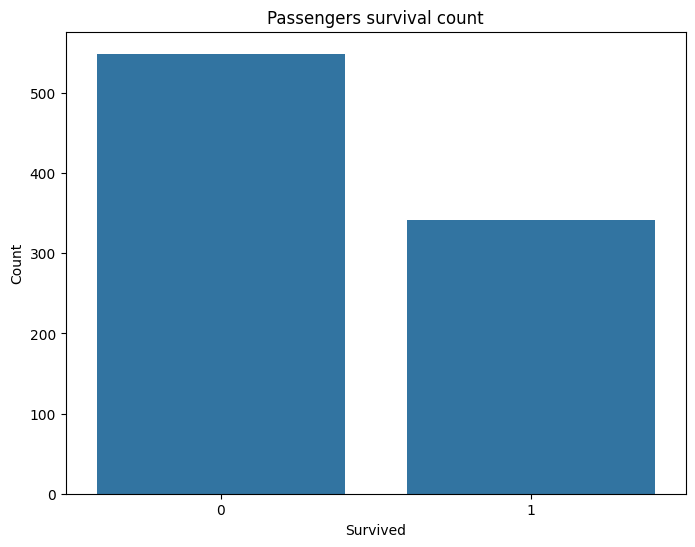

In [ ]:
#Univariate Visualization plot the count of passengers who survived vs who haven't survived
plt.figure(figsize=(8,6))
sns.countplot(x='Survived',data=titanic_df)
plt.title('Passengers survival count')
plt.xlabel('Survived')
plt.ylabel('Count')
plt.show()

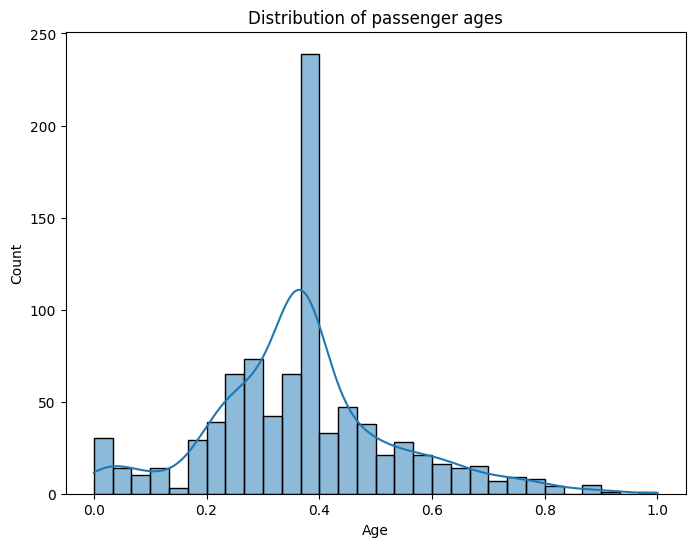

In [ ]:
#plot distribution of passenger ages
plt.figure(figsize=(8,6))
sns.histplot(x='Age',data=titanic_df,kde=True)
plt.title('Distribution of passenger ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

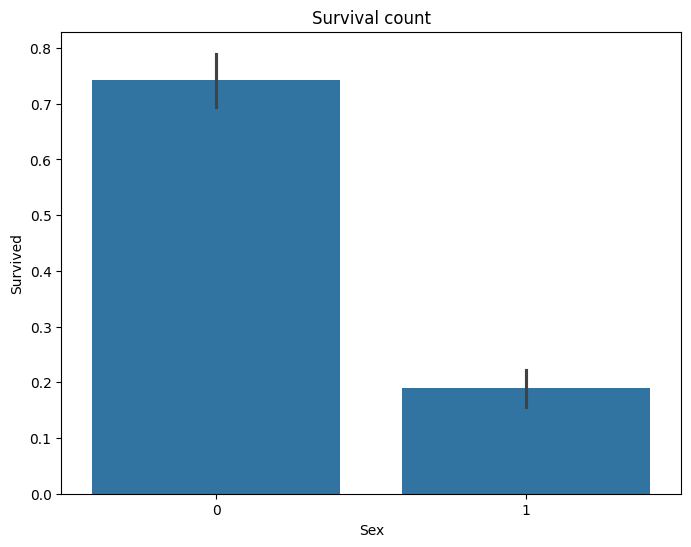

In [ ]:
#Bivariate Visualization(Bar chart of survival count)
plt.figure(figsize=(8,6))
sns.barplot(x='Sex',y='Survived',data=titanic_df)
plt.title('Survival count')
plt.xlabel('Sex')
plt.ylabel('Survived')
plt.show()

In [ ]:
from numpy import outer
#Outlier detection
Q1=titanic_df['Age'].quantile(0.25)
Q3=titanic_df['Age'].quantile(0.75)
IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
outliers=(titanic_df['Age']>=(lower_limit))&(titanic_df['Age']<=(upper_limit))
print(outliers.sum())

825


In [ ]:
print("Dataset shape after removing outliers:",titanic_df.shape)

Dataset shape after removing outliers: (891, 15)


In [ ]:
print('After preprocessing')
display(titanic_df.head())

After preprocessing


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",1,0.271174,1,0,A/5 21171,0.014151,False,False,True,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,0.472229,1,0,PC 17599,0.139136,True,False,False,2,0
2,3,1,3,"Heikkinen, Miss. Laina",0,0.321438,0,0,STON/O2. 3101282,0.015469,False,False,True,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,0.434531,1,0,113803,0.103644,False,False,True,2,0
4,5,0,3,"Allen, Mr. William Henry",1,0.434531,0,0,373450,0.015713,False,False,True,1,1
